In [1]:

# Step 1: Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




In [4]:
df=pd.read_csv("/content/drive/MyDrive/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [5]:
display(df.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (1470, 35)


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [9]:
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurre

In [10]:
print("\nAttrition counts:")
print(df["Attrition"].value_counts())

print("\nAttrition percentages:")
print(df["Attrition"].value_counts(normalize=True) * 100)



Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition percentages:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


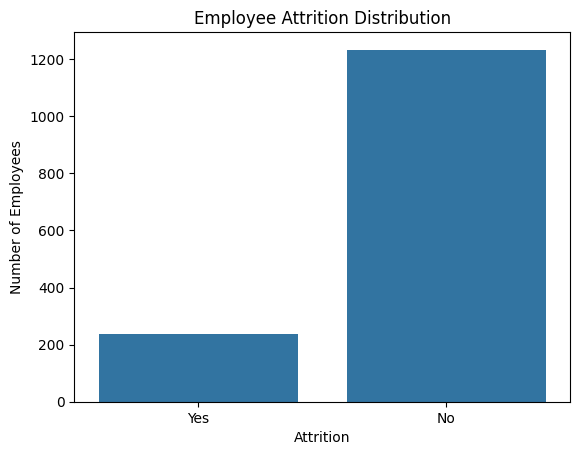

In [11]:
# Step 3.1: Visualize attrition counts

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()


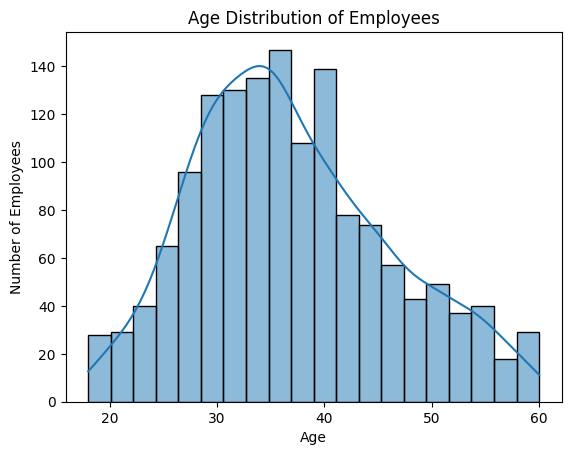

In [12]:

# Step 3.2: Understand the age distribution

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Age Distribution of Employees")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()


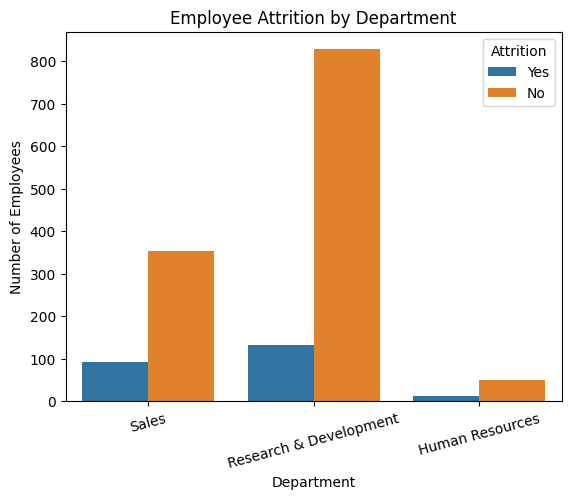

In [13]:

# Step 3.3: Attrition by department

sns.countplot(data=df, x="Department", hue="Attrition")

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=15)
plt.show()


Attrition                  No    Yes
Department                          
Human Resources         80.95  19.05
Research & Development  86.16  13.84
Sales                   79.37  20.63


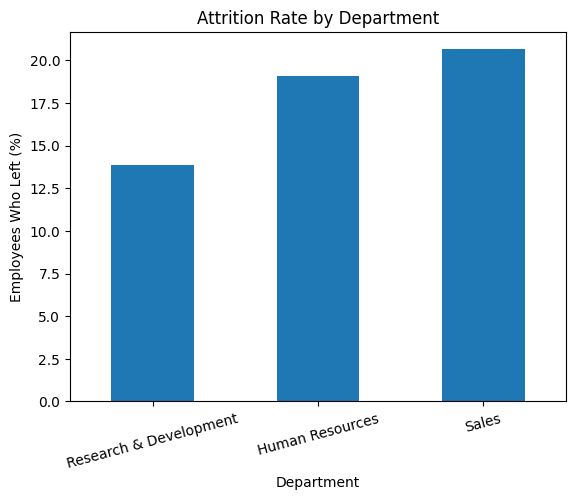

In [14]:

# Calculate attrition rate for each department

department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"],
    normalize="index"
) * 100

print(department_attrition.round(2))

# Plot the percentage who left
department_attrition["Yes"].sort_values().plot(
    kind="bar",
    title="Attrition Rate by Department",
    ylabel="Employees Who Left (%)",
    xlabel="Department"
)

plt.xticks(rotation=15)
plt.show()


In [15]:

# Step 4.1: Inspect the dataset

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nNumber of unique values in each column:")
print(df.nunique().sort_values())


Dataset shape: (1470, 35)

Data types:
Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours                int64
StockOptionLevel

In [16]:

# Step 4.2: Check these columns before removing them

columns_to_check = [
    "EmployeeCount",
    "Over18",
    "StandardHours",
    "EmployeeNumber"
]

display(df[columns_to_check].head())
print("\nUnique values:")
print(df[columns_to_check].nunique())


,EmployeeCount,Over18,StandardHours,EmployeeNumber
0,1,Y,80,1
1,1,Y,80,2
2,1,Y,80,4
3,1,Y,80,5
4,1,Y,80,7



Unique values:
EmployeeCount        1
Over18               1
StandardHours        1
EmployeeNumber    1470
dtype: int64


In [17]:

# Step 4.3: Remove irrelevant columns

df = df.drop(
    columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"]
)

# Separate input features (X) and target (y)

X = df.drop(columns=["Attrition"])
y = df["Attrition"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())


Features shape: (1470, 30)
Target shape: (1470,)


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,...,3,1,0,8,0,1,6,4,0,5
1,49,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,...,4,4,1,10,3,3,10,7,1,7
2,37,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,...,3,2,0,7,3,3,0,0,0,0
3,33,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,...,3,3,0,8,3,3,8,7,3,0
4,27,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,...,3,4,1,6,3,3,2,2,2,2


,Attrition
0,Yes
1,No
2,Yes
3,No
4,No


In [18]:

from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,
random_state=42,stratify=y)

# Check the sizes of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training features: (1176, 30)
Testing features: (294, 30)

Training target distribution:
Attrition
No     83.843537
Yes    16.156463
Name: proportion, dtype: float64

Testing target distribution:
Attrition
No     84.013605
Yes    15.986395
Name: proportion, dtype: float64


In [19]:

# Step 6.1: Identify feature types

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Select numerical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Select categorical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Numerical features:", numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:", categorical_features)


Number of numerical features: 23
Numerical features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Number of categorical features: 7
Categorical features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [20]:

# Step 6.2: Build the preprocessing pipeline

numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [21]:

# Step 7.1: Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create a pipeline combining preprocessing and the model
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [23]:
# Step 7.2: Predict attrition for unseen employees

y_pred = logistic_model.predict(X_test)

results = pd.DataFrame({
    "Actual Attrition": y_test.reset_index(drop=True),
    "Predicted Attrition": y_pred
})

display(results.head(10))



,Actual Attrition,Predicted Attrition
0,No,No
1,No,No
2,No,No
3,No,No
4,Yes,Yes
5,No,Yes
6,No,No
7,No,No
8,No,No
9,No,No


In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="Yes"
)

recall = recall_score(
    y_test, y_pred, pos_label="Yes"
)

f1 = f1_score(
    y_test, y_pred, pos_label="Yes"
)

# Print the results
print("Logistic Regression Evaluation")
print("-" * 35)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# ROC-AUC using the probability of Attrition = Yes
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(
    roc_auc_score((y_test == "Yes").astype(int), y_prob), 4
))


Logistic Regression Evaluation
-----------------------------------
Accuracy:  0.7517
Precision: 0.3488
Recall:    0.6383
F1-score:  0.4511

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.77      0.84       247
         Yes       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294

ROC-AUC: 0.8032


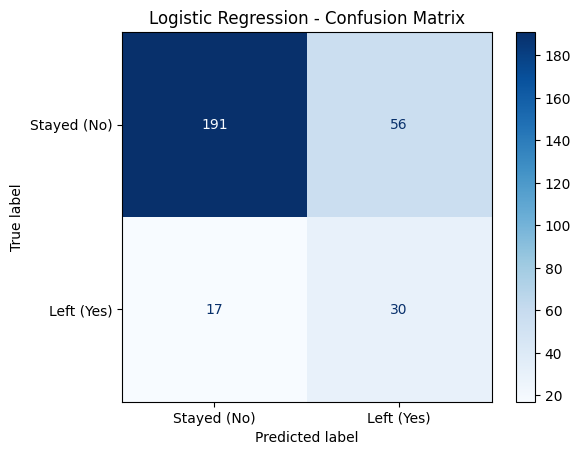

Confusion matrix:
[[191  56]
 [ 17  30]]


In [25]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

# Display the matrix as a heatmap
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (No)", "Left (Yes)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print("Confusion matrix:")
print(cm)


In [26]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

# Predict on the test set
y_pred_rf = rf_model.predict(X_test)

# Get probability scores for the "Yes" class
y_prob_rf = rf_model.predict_proba(X_test)[
    :, list(rf_model.named_steps["classifier"].classes_).index("Yes")
]

print("Predictions generated successfully!")


Random Forest model trained successfully!
Predictions generated successfully!


In [27]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

print("Random Forest Evaluation")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf, pos_label='Yes', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf, pos_label='Yes', zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf, pos_label='Yes', zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score((y_test == 'Yes').astype(int), y_prob_rf):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


Random Forest Evaluation
-----------------------------------
Accuracy:  0.8469
Precision: 0.6250
Recall:    0.1064
F1-score:  0.1818
ROC-AUC:   0.7832

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.99      0.92       247
         Yes       0.62      0.11      0.18        47

    accuracy                           0.85       294
   macro avg       0.74      0.55      0.55       294
weighted avg       0.82      0.85      0.80       294



In [28]:

%pip install -q xgboost

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

print("XGBoost imported successfully!")


XGBoost imported successfully!


In [29]:

# Create the XGBoost pipeline

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Convert target labels into binary values for XGBoost
y_train_xgb = (y_train == "Yes").astype(int)

# Train the model
xgb_model.fit(X_train, y_train_xgb)

print("XGBoost model trained successfully!")


XGBoost model trained successfully!


In [30]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Generate probabilities and predictions
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

# Convert actual labels into 0 and 1
y_test_xgb = (y_test == "Yes").astype(int)

print("XGBoost Evaluation")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test_xgb, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test_xgb, y_pred_xgb, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_xgb, y_pred_xgb, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test_xgb, y_pred_xgb, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_xgb, y_prob_xgb):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_xgb, y_pred_xgb,
    target_names=["No", "Yes"],
    zero_division=0
))


XGBoost Evaluation
-----------------------------------
Accuracy:  0.8673
Precision: 0.7857
Recall:    0.2340
F1-score:  0.3607
ROC-AUC:   0.7973

Classification Report:
              precision    recall  f1-score   support

          No       0.87      0.99      0.93       247
         Yes       0.79      0.23      0.36        47

    accuracy                           0.87       294
   macro avg       0.83      0.61      0.64       294
weighted avg       0.86      0.87      0.84       294



In [31]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics for Attrition = Yes
f1_yes_scorer = make_scorer(
    f1_score,
    pos_label="Yes"
)

scoring = {
    "f1_yes": f1_yes_scorer,
    "roc_auc": "roc_auc"
}

# Evaluate Logistic Regression
lr_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Evaluate Random Forest
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Evaluate XGBoost
xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train_xgb,
    cv=cv,
    scoring={
        "f1_yes": make_scorer(f1_score, pos_label=1),
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

# Summarize cross-validation results
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Mean CV F1 (Yes)": [
        lr_cv["test_f1_yes"].mean(),
        rf_cv["test_f1_yes"].mean(),
        xgb_cv["test_f1_yes"].mean()
    ],
    "F1 Std Dev": [
        lr_cv["test_f1_yes"].std(),
        rf_cv["test_f1_yes"].std(),
        xgb_cv["test_f1_yes"].std()
    ],
    "Mean CV ROC-AUC": [
        lr_cv["test_roc_auc"].mean(),
        rf_cv["test_roc_auc"].mean(),
        xgb_cv["test_roc_auc"].mean()
    ]
})

display(cv_results.round(4))


,Model,Mean CV F1 (Yes),F1 Std Dev,Mean CV ROC-AUC
0,Logistic Regression,0.4925,0.0337,0.8273
1,Random Forest,0.2835,0.0779,0.8043
2,XGBoost,0.4704,0.0835,0.8203


In [32]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score
import numpy as np

# Generate predictions for training rows using models
# that did not train on the corresponding validation fold
oof_probabilities = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Find which probability column represents "Yes"
yes_index = list(logistic_model.classes_).index("Yes")
oof_prob_yes = oof_probabilities[:, yes_index]

print("Out-of-fold probabilities generated.")
print("Number of probabilities:", len(oof_prob_yes))


Out-of-fold probabilities generated.
Number of probabilities: 1176


In [33]:

# Try different decision thresholds
thresholds = np.arange(0.10, 0.71, 0.01)

f1_scores = []

for threshold in thresholds:
    oof_predictions = np.where(
        oof_prob_yes >= threshold,
        "Yes",
        "No"
    )

    score = f1_score(
        y_train,
        oof_predictions,
        pos_label="Yes"
    )

    f1_scores.append(score)

# Select the threshold with the highest cross-validated F1
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_cv_f1 = f1_scores[best_index]

print("Best threshold:", round(best_threshold, 2))
print("Best training OOF F1-score:", round(best_cv_f1, 4))


Best threshold: 0.69
Best training OOF F1-score: 0.57


In [34]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Obtain test probabilities from the trained Logistic Regression model
test_prob_yes = logistic_model.predict_proba(X_test)[:, yes_index]

# Apply the threshold selected using training cross-validation
y_pred_lr_tuned = np.where(
    test_prob_yes >= best_threshold,
    "Yes",
    "No"
)

print("Logistic Regression — Tuned Threshold")
print("-" * 42)
print(f"Threshold: {best_threshold:.2f}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr_tuned, pos_label='Yes', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr_tuned, pos_label='Yes', zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_lr_tuned, pos_label='Yes', zero_division=0):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_lr_tuned, labels=["No", "Yes"]))

print("\nClassification report:")
print(classification_report(y_test, y_pred_lr_tuned, zero_division=0))


Logistic Regression — Tuned Threshold
------------------------------------------
Threshold: 0.69
Accuracy:  0.8367
Precision: 0.4884
Recall:    0.4468
F1-score:  0.4667

Confusion matrix:
[[225  22]
 [ 26  21]]

Classification report:
              precision    recall  f1-score   support

          No       0.90      0.91      0.90       247
         Yes       0.49      0.45      0.47        47

    accuracy                           0.84       294
   macro avg       0.69      0.68      0.69       294
weighted avg       0.83      0.84      0.83       294



Top 15 features by absolute coefficient:


,Feature,Coefficient,Absolute Coefficient
42,cat__JobRole_Research Director,-1.465683,1.465683
39,cat__JobRole_Laboratory Technician,1.194333,1.194333
45,cat__JobRole_Sales Representative,1.120617,1.120617
23,cat__BusinessTravel_Non-Travel,-0.993885,0.993885
49,cat__OverTime_No,-0.892809,0.892809
33,cat__EducationField_Other,-0.798108,0.798108
24,cat__BusinessTravel_Travel_Frequently,0.787566,0.787566
50,cat__OverTime_Yes,0.761522,0.761522
29,cat__EducationField_Human Resources,0.721129,0.721129
37,cat__JobRole_Healthcare Representative,-0.647202,0.647202


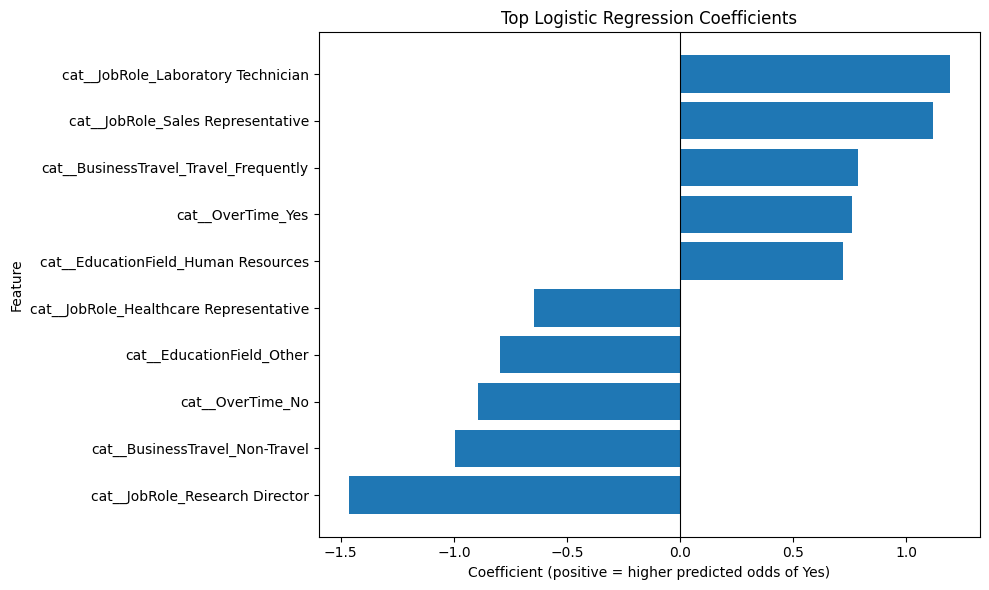

In [35]:

# Step 16: Interpret Logistic Regression coefficients

import pandas as pd
import matplotlib.pyplot as plt

# Get the names of the transformed features
feature_names = (
    logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get the model coefficients
coefficients = (
    logistic_model
    .named_steps["classifier"]
    .coef_[0]
)

# Create a table of features and coefficients
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print("Top 15 features by absolute coefficient:")
display(feature_importance.head(15))

# Plot the 10 largest coefficients by absolute magnitude
top_features = feature_importance.head(10).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top Logistic Regression Coefficients")
plt.xlabel("Coefficient (positive = higher predicted odds of Yes)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
